# Exploratory Data Analysis

This notebook explores the prepared dataset before regression modelling.

In [79]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

In [80]:
# Load prepared dataset
df = pd.read_csv("Regression_2_2_Final_Model_Data.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [81]:
# Define target
target = "Goals_For"

# Define 8 predictors
features = [
    "Team_PreTournament_FIFA_Rank",
    "Opponent_PreTournament_FIFA_Rank",
    "Team_PreMatch_Goals_PG",
    "Opponent_PreMatch_GoalsAgainst_PG",
    "Team_PreMatch_GoalsAgainst_PG",
    "Opponent_PreMatch_Points_PG",
    "Team_PreMatch_Possession_Avg",
    "Team_PreMatch_Points_PG"
]

print("Target:", target)
print("Number of predictors:", len(features))

Target: Goals_For
Number of predictors: 8


In [82]:
# Check dataset structure
print("Dataset shape:", df.shape)
print("Unique matches:", df["MatchID"].nunique())
print("Unique teams:", df["Team"].nunique())
print(
    "Duplicate team-match rows:",
    df.duplicated(["MatchID", "Team"]).sum()
)

print("\nRows per match:")
print(df.groupby("MatchID").size().value_counts())

Dataset shape: (208, 12)
Unique matches: 104
Unique teams: 48
Duplicate team-match rows: 0

Rows per match:
2    104
Name: count, dtype: int64


In [83]:
# Check data types
df.dtypes

MatchID                                int64
Team                                     str
Opponent                                 str
Team_PreTournament_FIFA_Rank           int64
Opponent_PreTournament_FIFA_Rank       int64
Team_PreMatch_Goals_PG               float64
Opponent_PreMatch_GoalsAgainst_PG    float64
Team_PreMatch_GoalsAgainst_PG        float64
Opponent_PreMatch_Points_PG          float64
Team_PreMatch_Possession_Avg         float64
Team_PreMatch_Points_PG              float64
Goals_For                              int64
dtype: object

In [84]:
# Check missing values
df.isnull().sum()

MatchID                               0
Team                                  0
Opponent                              0
Team_PreTournament_FIFA_Rank          0
Opponent_PreTournament_FIFA_Rank      0
Team_PreMatch_Goals_PG               48
Opponent_PreMatch_GoalsAgainst_PG    48
Team_PreMatch_GoalsAgainst_PG        48
Opponent_PreMatch_Points_PG          48
Team_PreMatch_Possession_Avg         48
Team_PreMatch_Points_PG              48
Goals_For                             0
dtype: int64

The six historical predictors each contain 48 missing values because each team's first tournament match has no previous tournament history.

These values are retained during EDA and will be handled later during model preprocessing.

In [85]:
# Descriptive statistics
descriptive_stats = df[features + [target]].describe().T

descriptive_stats

,count,mean,std,min,25%,50%,75%,max
Team_PreTournament_FIFA_Rank,208.0,27.759615,22.945217,1.0,8.750000,22.500000,41.000000,85.0
Opponent_PreTournament_FIFA_Rank,208.0,27.759615,22.945217,1.0,8.750000,22.500000,41.000000,85.0
Team_PreMatch_Goals_PG,160.0,1.728170,1.106078,0.0,1.000000,1.708333,2.333333,7.0
Opponent_PreMatch_GoalsAgainst_PG,160.0,1.269524,1.097220,0.0,0.592857,1.000000,1.700000,7.0
Team_PreMatch_GoalsAgainst_PG,160.0,1.269524,1.097220,0.0,0.592857,1.000000,1.700000,7.0
Opponent_PreMatch_Points_PG,160.0,1.657946,1.015441,0.0,1.000000,1.666667,2.500000,3.0
Team_PreMatch_Possession_Avg,160.0,52.286057,11.551605,25.0,45.666667,54.000000,61.000000,75.5
Team_PreMatch_Points_PG,160.0,1.657946,1.015441,0.0,1.000000,1.666667,2.500000,3.0
Goals_For,208.0,1.480769,1.393434,0.0,0.000000,1.000000,2.000000,7.0


In [86]:
# Create summary table
eda_summary = pd.DataFrame({
    "Count": df[features + [target]].count(),
    "Missing": df[features + [target]].isnull().sum(),
    "Mean": df[features + [target]].mean(),
    "Std": df[features + [target]].std(),
    "Min": df[features + [target]].min(),
    "Median": df[features + [target]].median(),
    "Max": df[features + [target]].max()
})

eda_summary.round(2)

,Count,Missing,Mean,Std,Min,Median,Max
Team_PreTournament_FIFA_Rank,208,0,27.76,22.95,1.0,22.50,85.0
Opponent_PreTournament_FIFA_Rank,208,0,27.76,22.95,1.0,22.50,85.0
Team_PreMatch_Goals_PG,160,48,1.73,1.11,0.0,1.71,7.0
Opponent_PreMatch_GoalsAgainst_PG,160,48,1.27,1.10,0.0,1.00,7.0
Team_PreMatch_GoalsAgainst_PG,160,48,1.27,1.10,0.0,1.00,7.0
Opponent_PreMatch_Points_PG,160,48,1.66,1.02,0.0,1.67,3.0
Team_PreMatch_Possession_Avg,160,48,52.29,11.55,25.0,54.00,75.5
Team_PreMatch_Points_PG,160,48,1.66,1.02,0.0,1.67,3.0
Goals_For,208,0,1.48,1.39,0.0,1.00,7.0


In [87]:
# Target summary
print("Mean goals:", round(df[target].mean(), 2))
print("Median goals:", df[target].median())
print("Variance:", round(df[target].var(), 2))
print("Standard deviation:", round(df[target].std(), 2))
print("Minimum goals:", df[target].min())
print("Maximum goals:", df[target].max())
print("Skewness:", round(df[target].skew(), 3))

Mean goals: 1.48
Median goals: 1.0
Variance: 1.94
Standard deviation: 1.39
Minimum goals: 0
Maximum goals: 7
Skewness: 1.149


In [88]:
# Count each goals value
goal_counts = df[target].value_counts().sort_index()

goal_counts

Goals_For
0    55
1    71
2    39
3    25
4    10
5     5
6     2
7     1
Name: count, dtype: int64

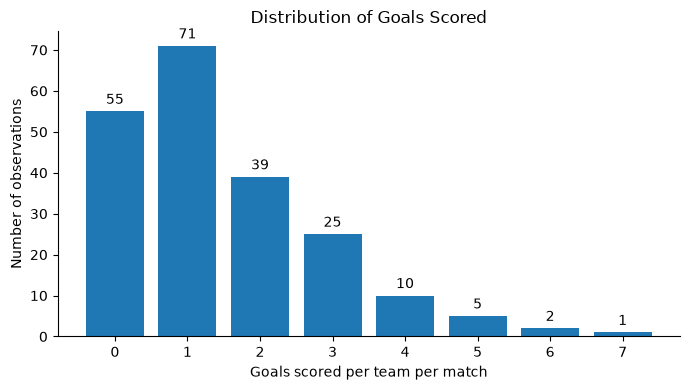

In [89]:
# Check target distribution
plt.figure(figsize=(7, 4))

bars = plt.bar(goal_counts.index, goal_counts.values)

plt.bar_label(bars, padding=3)

plt.title("Distribution of Goals Scored")
plt.xlabel("Goals scored per team per match")
plt.ylabel("Number of observations")

plt.gca().spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

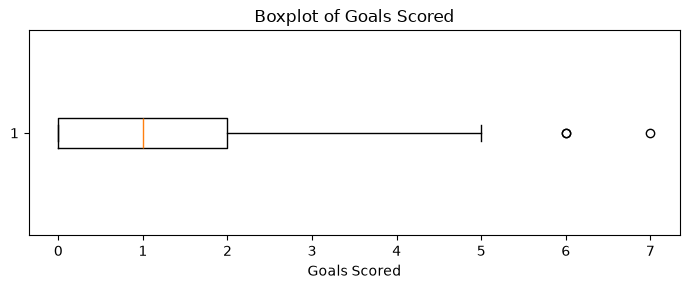

In [90]:
# Check target spread
plt.figure(figsize=(7, 3))

plt.boxplot(df[target], orientation="horizontal")

plt.title("Boxplot of Goals Scored")
plt.xlabel("Goals Scored")
plt.tight_layout()
plt.show()

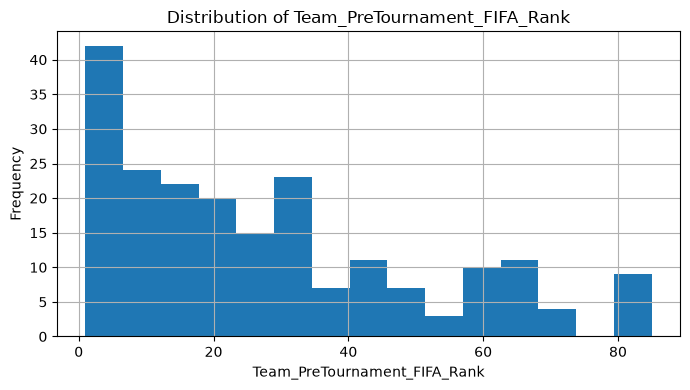

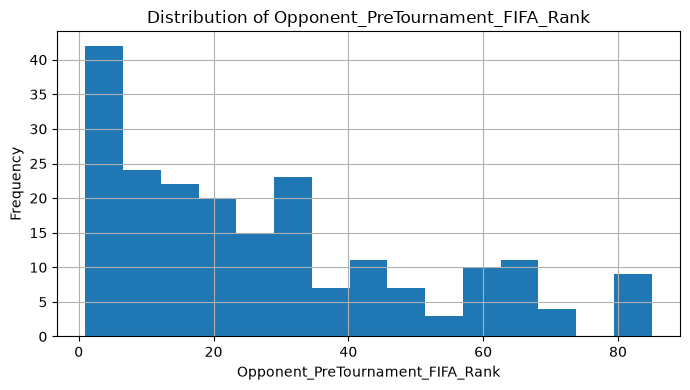

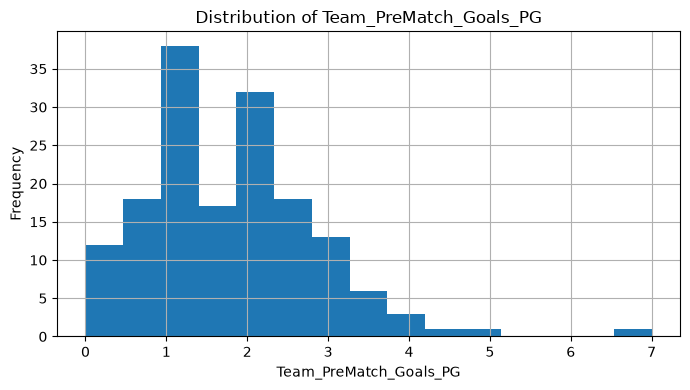

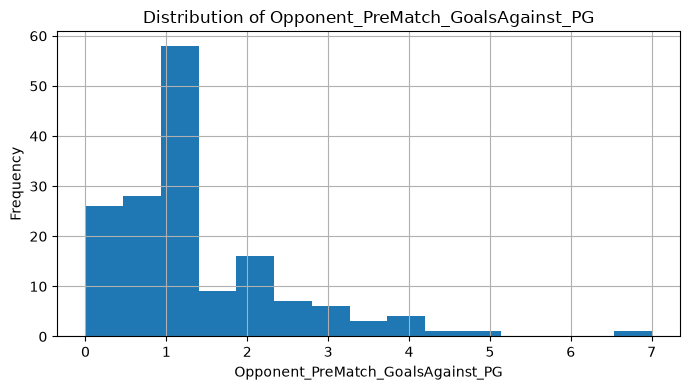

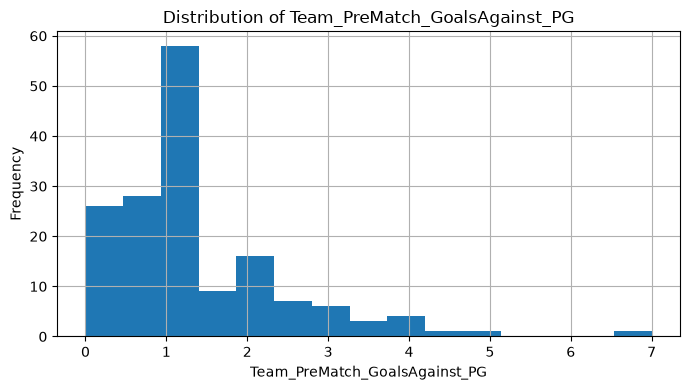

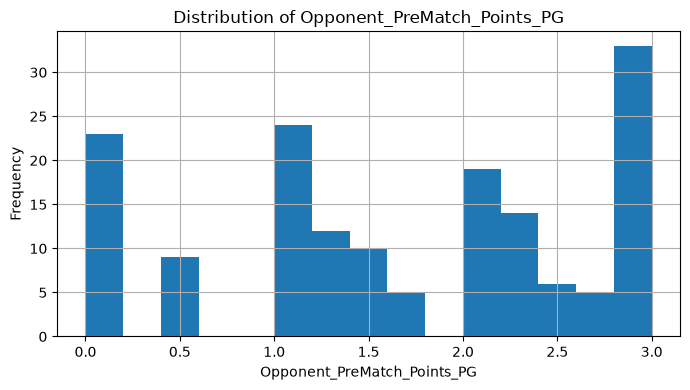

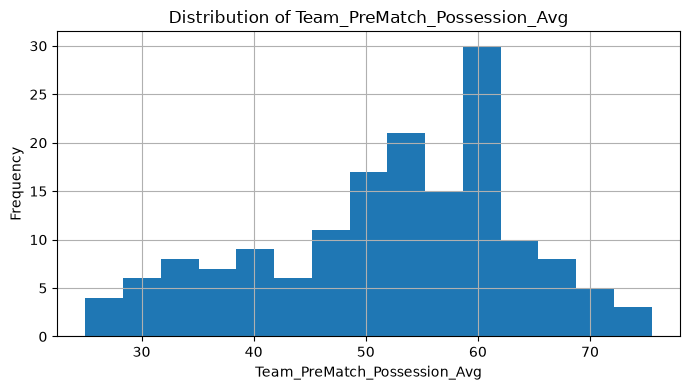

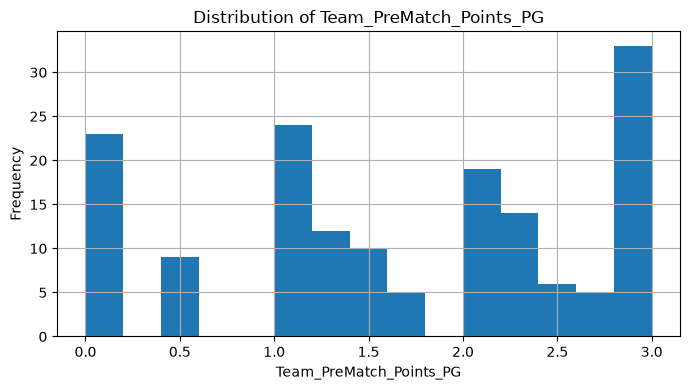

In [91]:
# Plot predictor distributions
for feature in features:
    plt.figure(figsize=(7, 4))

    df[feature].dropna().hist(bins=15)

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

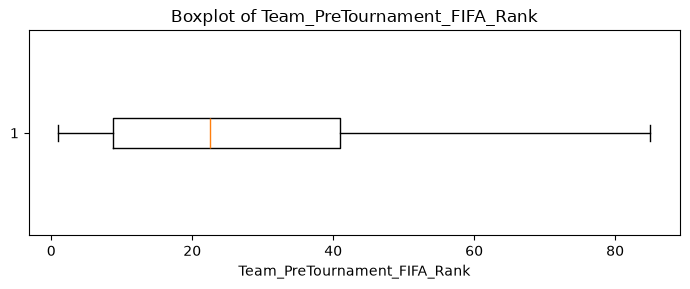

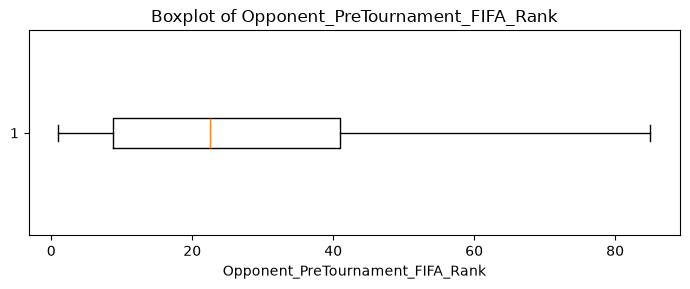

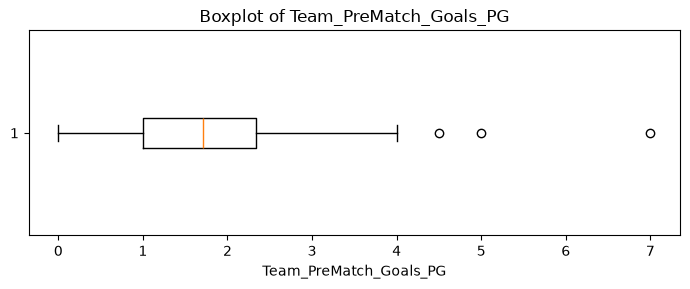

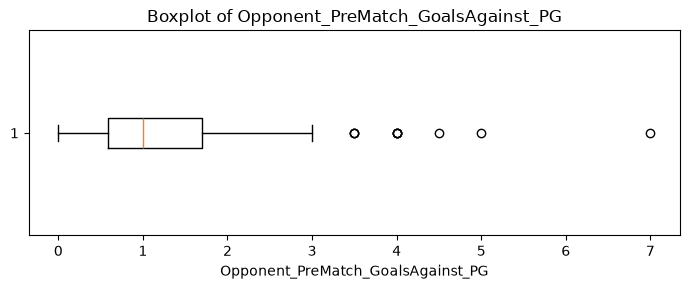

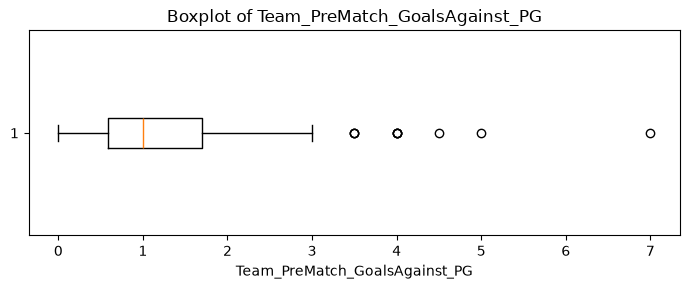

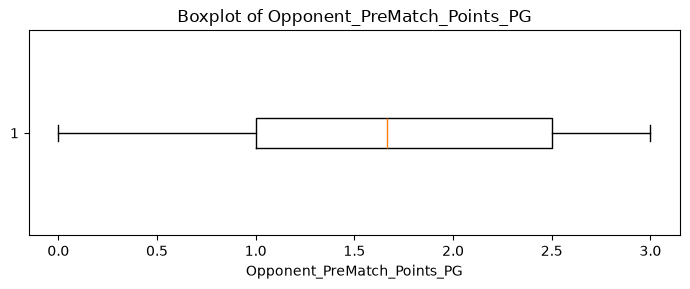

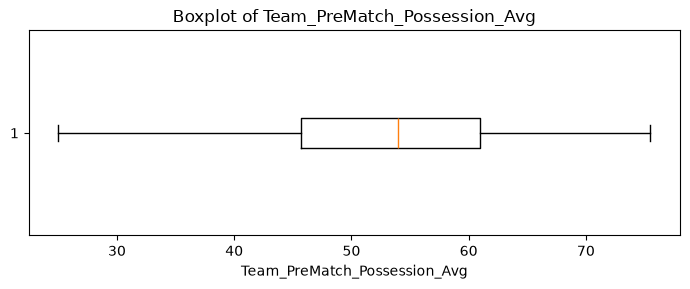

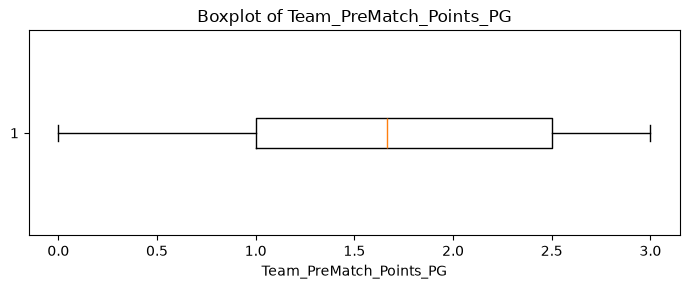

In [92]:
# Check predictor spread and possible outliers
for feature in features:
    plt.figure(figsize=(7, 3))

    plt.boxplot(
        df[feature].dropna(),
        orientation="horizontal"
    )

    plt.title(f"Boxplot of {feature}")
    plt.xlabel(feature)
    plt.tight_layout()
    plt.show()

In [93]:
# Count possible outliers using the IQR rule
outlier_results = []

for feature in features:
    values = df[feature].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = values[
        (values < lower) | (values > upper)
    ]

    outlier_results.append({
        "Variable": feature,
        "Possible_Outliers": len(outliers)
    })

outlier_summary = pd.DataFrame(outlier_results)

outlier_summary

,Variable,Possible_Outliers
0,Team_PreTournament_FIFA_Rank,0
1,Opponent_PreTournament_FIFA_Rank,0
2,Team_PreMatch_Goals_PG,3
3,Opponent_PreMatch_GoalsAgainst_PG,10
4,Team_PreMatch_GoalsAgainst_PG,10
5,Opponent_PreMatch_Points_PG,0
6,Team_PreMatch_Possession_Avg,0
7,Team_PreMatch_Points_PG,0


Possible outliers identified during EDA are not automatically removed because unusual values may represent valid football performances.

Their effect will be considered during regression diagnostics.

In [94]:
# Find rows with missing predictors
missing_history_rows = df[
    df[features].isnull().any(axis=1)
]

print(
    "Rows with at least one missing predictor:",
    len(missing_history_rows)
)

print(
    "Unique teams in these rows:",
    missing_history_rows["Team"].nunique()
)

Rows with at least one missing predictor: 48
Unique teams in these rows: 48


In [95]:
# Check missing history occurs once per team
missing_per_team = (
    missing_history_rows
    .groupby("Team")
    .size()
)

print(missing_per_team.value_counts())

1    48
Name: count, dtype: int64


In [96]:
# Use complete rows for consistent correlation analysis
complete_eda = df.dropna(subset=features).copy()

print("Complete observations:", len(complete_eda))

Complete observations: 160


In [97]:
# Calculate correlations using complete observations
correlation_matrix = (
    complete_eda[features + [target]]
    .corr()
)

correlation_matrix.round(3)

,Team_PreTournament_FIFA_Rank,Opponent_PreTournament_FIFA_Rank,Team_PreMatch_Goals_PG,Opponent_PreMatch_GoalsAgainst_PG,Team_PreMatch_GoalsAgainst_PG,Opponent_PreMatch_Points_PG,Team_PreMatch_Possession_Avg,Team_PreMatch_Points_PG,Goals_For
Team_PreTournament_FIFA_Rank,1.000,-0.119,-0.486,0.055,0.440,-0.169,-0.686,-0.564,-0.385
Opponent_PreTournament_FIFA_Rank,-0.119,1.000,-0.119,0.440,0.055,-0.564,0.004,-0.169,0.367
Team_PreMatch_Goals_PG,-0.486,-0.119,1.000,-0.182,-0.197,0.225,0.387,0.708,0.111
Opponent_PreMatch_GoalsAgainst_PG,0.055,0.440,-0.182,1.000,0.114,-0.635,-0.111,-0.248,0.215
Team_PreMatch_GoalsAgainst_PG,0.440,0.055,-0.197,0.114,1.000,-0.248,-0.356,-0.635,-0.163
Opponent_PreMatch_Points_PG,-0.169,-0.564,0.225,-0.635,-0.248,1.000,0.118,0.357,-0.189
Team_PreMatch_Possession_Avg,-0.686,0.004,0.387,-0.111,-0.356,0.118,1.000,0.389,0.313
Team_PreMatch_Points_PG,-0.564,-0.169,0.708,-0.248,-0.635,0.357,0.389,1.000,0.111
Goals_For,-0.385,0.367,0.111,0.215,-0.163,-0.189,0.313,0.111,1.000


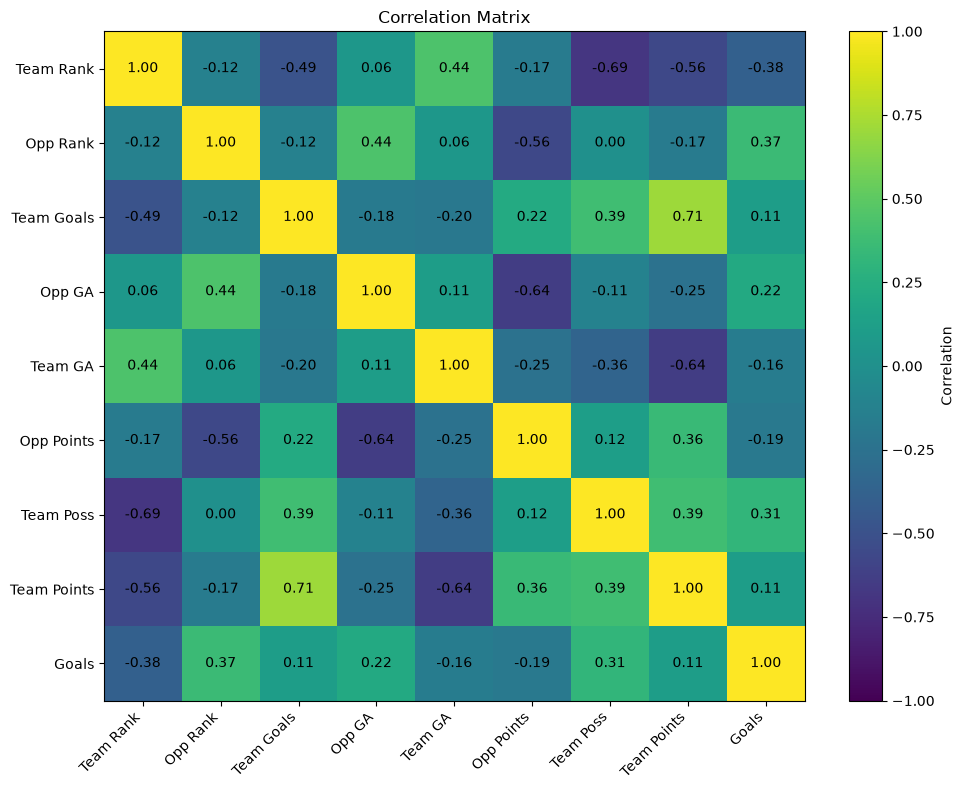

In [98]:
# Short labels for heatmap
short_labels = [
    "Team Rank",
    "Opp Rank",
    "Team Goals",
    "Opp GA",
    "Team GA",
    "Opp Points",
    "Team Poss",
    "Team Points",
    "Goals"
]

plt.figure(figsize=(10, 8))

plt.imshow(
    correlation_matrix,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(short_labels)),
    short_labels,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(short_labels)),
    short_labels
)

# Add correlation values
for i in range(len(short_labels)):
    for j in range(len(short_labels)):
        plt.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

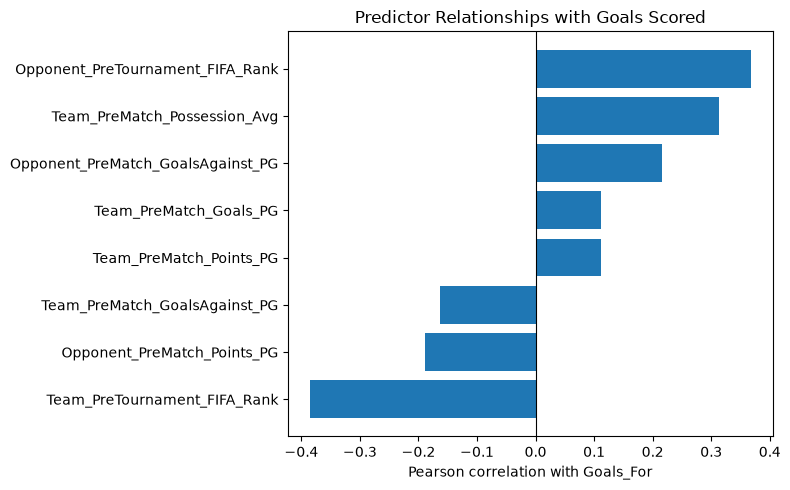

In [99]:
# Plot target-correlation ranking chart
target_corr = (
    complete_eda[features + [target]]
    .corr()[target]
    .drop(target)
    .sort_values()
)

plt.figure(figsize=(8, 5))

plt.barh(target_corr.index, target_corr.values)

plt.axvline(0, color="black", linewidth=0.8)

plt.xlabel("Pearson correlation with Goals_For")
plt.title("Predictor Relationships with Goals Scored")

plt.tight_layout()
plt.show()

In [100]:
# Find strongly correlated predictor pairs
predictor_corr = complete_eda[features].corr()

strong_pairs = []

for i in range(len(features)):
    for j in range(i + 1, len(features)):

        corr = predictor_corr.iloc[i, j]

        if abs(corr) >= 0.70:
            strong_pairs.append({
                "Variable_1": features[i],
                "Variable_2": features[j],
                "Correlation": round(corr, 3)
            })

strong_corr_df = pd.DataFrame(strong_pairs)

if len(strong_corr_df) == 0:
    print("No predictor pairs have |correlation| >= 0.70.")
else:
    display(strong_corr_df)

,Variable_1,Variable_2,Correlation
0,Team_PreMatch_Goals_PG,Team_PreMatch_Points_PG,0.708


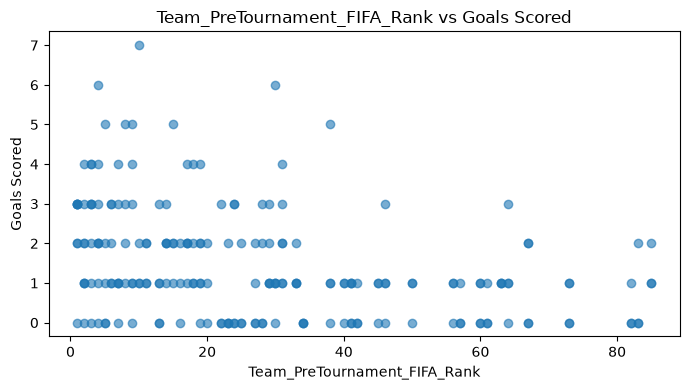

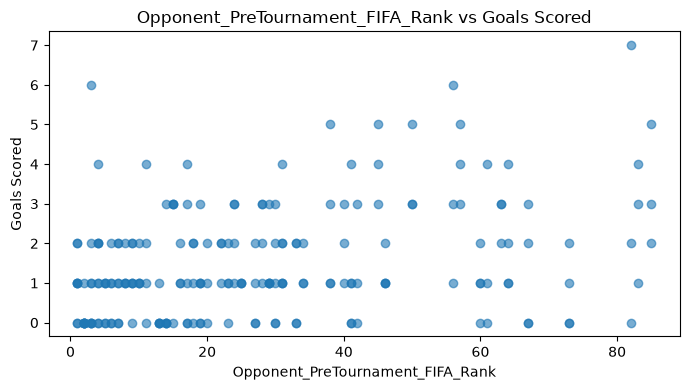

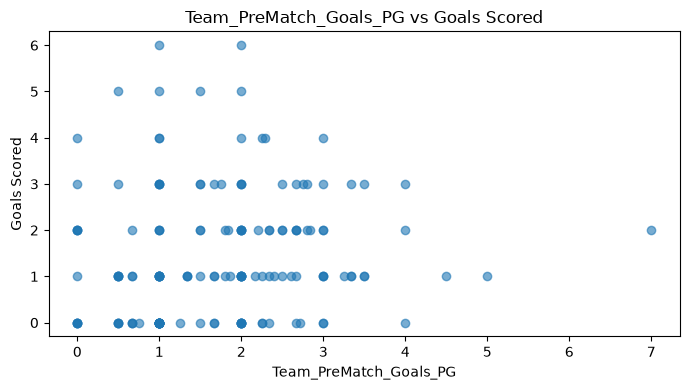

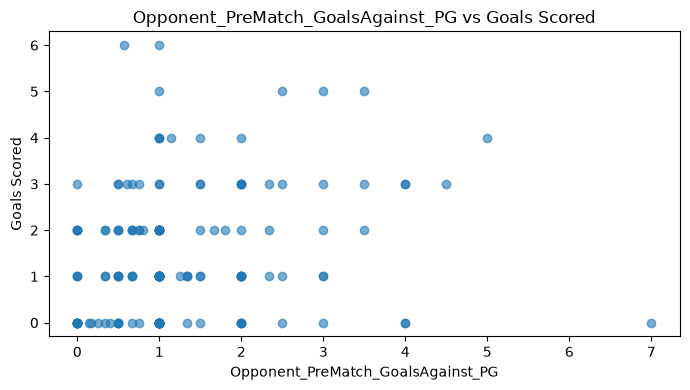

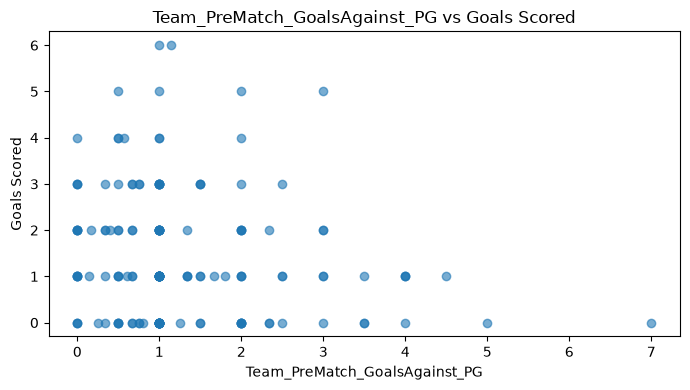

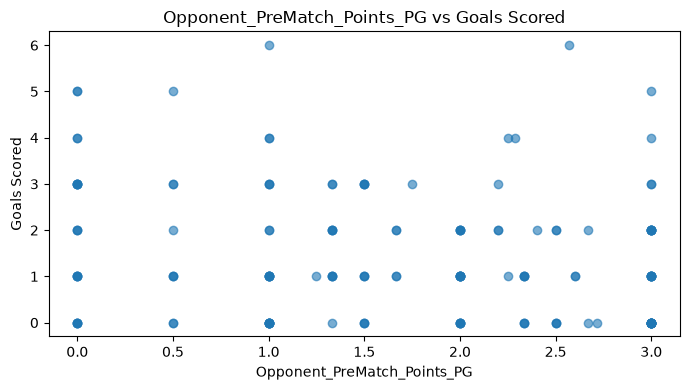

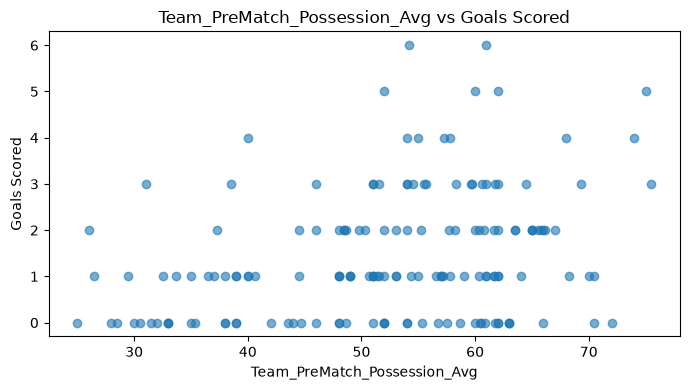

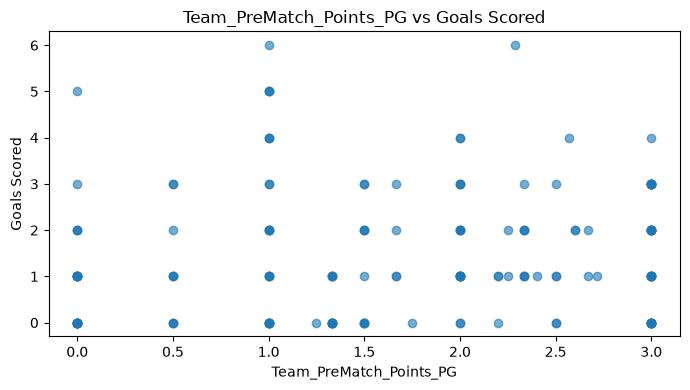

In [101]:
# Plot predictors against goals scored
for feature in features:
    temp = df[[feature, target]].dropna()

    plt.figure(figsize=(7, 4))

    plt.scatter(
        temp[feature],
        temp[target],
        alpha=0.6
    )

    plt.title(f"{feature} vs Goals Scored")
    plt.xlabel(feature)
    plt.ylabel("Goals Scored")
    plt.tight_layout()
    plt.show()

In [102]:
# Check FIFA ranking relationship with goals
team_rank_corr = (
    df[
        ["Team_PreTournament_FIFA_Rank", target]
    ]
    .corr()
    .iloc[0, 1]
)

opponent_rank_corr = (
    df[
        ["Opponent_PreTournament_FIFA_Rank", target]
    ]
    .corr()
    .iloc[0, 1]
)

print(
    "Team FIFA rank vs goals:",
    round(team_rank_corr, 3)
)

print(
    "Opponent FIFA rank vs goals:",
    round(opponent_rank_corr, 3)
)

Team FIFA rank vs goals: -0.367
Opponent FIFA rank vs goals: 0.345


In [103]:
# Confirm each match has exactly two observations
rows_per_match = df.groupby("MatchID").size()

print("Matches with exactly two rows:",
      (rows_per_match == 2).sum())

print("Matches with another number of rows:",
      (rows_per_match != 2).sum())

Matches with exactly two rows: 104
Matches with another number of rows: 0


Each match contributes two related observations, one for each team.

Therefore, the later train-test split and cross-validation should be grouped by `MatchID` so that both observations from the same match remain in the same data partition.

In [104]:
# Final checks
assert df.shape == (208, 12)
assert df["MatchID"].nunique() == 104
assert df["Team"].nunique() == 48
assert df.groupby("MatchID").size().eq(2).all()
assert len(features) == 8
assert df[target].isnull().sum() == 0

assert (
    df["Team_PreTournament_FIFA_Rank"]
    .isnull()
    .sum()
    == 0
)

assert (
    df["Opponent_PreTournament_FIFA_Rank"]
    .isnull()
    .sum()
    == 0
)

assert len(missing_history_rows) == 48
assert len(complete_eda) == 160

print("EDA validation completed successfully.")

EDA validation completed successfully.


# EDA Summary

The exploratory analysis examined the target variable and all eight explanatory variables using descriptive statistics, distributions, boxplots, outlier checks, correlations and predictor-target relationships.

The six historical predictors contain 48 expected missing observations corresponding to each team's first tournament match. These observations remain in the dataset and will be handled during model preprocessing.

The match structure also shows that each match contributes two related observations. Therefore, model splitting and cross-validation will be grouped by MatchID to keep both sides of each match together.

The data is ready to proceed to regression preprocessing and modelling.